In [58]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lthnhcng/imbd-datasets/IMDB Dataset.csv


# 12. Core Implementation Tokenization

In [59]:
from transformers import AutoTokenizer, AutoModel

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

texts = [
    "I really like this movie",
    "This movie is terrible"
]

tokens = tokenizer(
    texts,
    padding=True,
    truncation=True,
    return_tensor="pt"
)

print(tokens.keys())

KeysView({'input_ids': [[101, 1045, 2428, 2066, 2023, 3185, 102], [101, 2023, 3185, 2003, 6659, 102, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 0]]})


In [60]:
print(tokens["input_ids"])

[[101, 1045, 2428, 2066, 2023, 3185, 102], [101, 2023, 3185, 2003, 6659, 102, 0]]


In [61]:
print(tokens["attention_mask"])

[[1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 0]]


In [62]:
# 2 cau co do dai khac nhau
texts = [
    "I love this movie",
    "The movie is very bad and disappointing.",
    "The film is too long"
]

tokens = tokenizer(
    texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print("Input IDs:")
print(tokens["input_ids"])

print("Attention Mask:")
print(tokens["attention_mask"])

Input IDs:
tensor([[  101,  1045,  2293,  2023,  3185,   102,     0,     0,     0,     0],
        [  101,  1996,  3185,  2003,  2200,  2919,  1998, 15640,  1012,   102],
        [  101,  1996,  2143,  2003,  2205,  2146,   102,     0,     0,     0]])
Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0]])


# 13. Core Implementation — Classification Head

In [63]:
from transformers import AutoModel

model_name = "bert-base-uncased"

bert = AutoModel.from_pretrained(model_name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [64]:
print(bert)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [65]:
outputs = bert(
    input_ids = tokens["input_ids"],
    attention_mask = tokens["attention_mask"]
)

print(outputs.last_hidden_state.shape)

torch.Size([3, 10, 768])


In [66]:
print(type(outputs))

<class 'transformers.modeling_outputs.BaseModelOutputWithPoolingAndCrossAttentions'>


In [67]:
print(outputs.last_hidden_state[0,:, :].shape)

torch.Size([10, 768])


In [68]:
# trich xuat [cls] representation
cls_representation = outputs.last_hidden_state[:, 0, :]

print(cls_representation.shape)

torch.Size([3, 768])


In [69]:
import torch.nn as nn
num_classes = 2
hidden_size = 768

classifier = nn.Linear(
    hidden_size,
    num_classes
)

In [70]:
logits = classifier(cls_representation)

print(logits.shape)

torch.Size([3, 2])


In [71]:
import torch
prob = torch.softmax(logits, dim=-1)

print(prob)

tensor([[0.6877, 0.3123],
        [0.6478, 0.3522],
        [0.7190, 0.2810]], grad_fn=<SoftmaxBackward0>)


In [72]:
predictions = torch.argmax(
    prob, dim=-1
)

print(predictions)

tensor([0, 0, 0])


In [73]:
label_mapping = {
    0: "Negative",
    1: "Positive"
}

for prediction in predictions:
    print(label_mapping[prediction.item()])

Negative
Negative
Negative


# Prepare Datasets for experiment 1 

In [5]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.master("local[*]").appName("Finetune").config("spark.driver.memory", "8g").getOrCreate()

In [6]:
path = "/kaggle/input/datasets/lthnhcng/imbd-datasets/IMDB Dataset.csv"

spdf = spark.read.csv(path, header=True, multiLine=True, escape='"')

spdf.show(5)

+--------------------+---------+
|              review|sentiment|
+--------------------+---------+
|One of the other ...| positive|
|A wonderful littl...| positive|
|I thought this wa...| positive|
|Basically there's...| negative|
|Petter Mattei's "...| positive|
+--------------------+---------+
only showing top 5 rows


In [7]:
from pyspark.ml.feature import RegexTokenizer

tokenizer = RegexTokenizer(
    inputCol = "review",
    outputCol = "words",
    pattern = r"[\S.,?!:;\"/)(><\\]+",
    gaps = False
)

words_df = tokenizer.transform(spdf)

words_df.show(5)

+--------------------+---------+--------------------+
|              review|sentiment|               words|
+--------------------+---------+--------------------+
|One of the other ...| positive|[one, of, the, ot...|
|A wonderful littl...| positive|[a, wonderful, li...|
|I thought this wa...| positive|[i, thought, this...|
|Basically there's...| negative|[basically, there...|
|Petter Mattei's "...| positive|[petter, mattei's...|
+--------------------+---------+--------------------+
only showing top 5 rows


In [8]:
from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(
    inputCol="sentiment",
    outputCol="label",
    handleInvalid = "skip"
)

indexer_model = indexer.fit(words_df)

df_index = indexer_model.transform(words_df)

df_index.show(5)

+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|One of the other ...| positive|[one, of, the, ot...|  1.0|
|A wonderful littl...| positive|[a, wonderful, li...|  1.0|
|I thought this wa...| positive|[i, thought, this...|  1.0|
|Basically there's...| negative|[basically, there...|  0.0|
|Petter Mattei's "...| positive|[petter, mattei's...|  1.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


In [9]:
train_set, val_set, test_set = df_index.randomSplit(
    [0.6, 0.2, 0.2]
)

train_set.show(5)

+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|\b\b\b\bA Turkish...| positive|[\b\b\b\ba, turki...|  1.0|
|!!!! MILD SPOILER...| negative|[!!!!, mild, spoi...|  0.0|
|!!!!! OF COURSE T...| negative|[!!!!!, of, cours...|  0.0|
|!!!!! POSSIBLE SP...| negative|[!!!!!, possible,...|  0.0|
|" I have wrestled...| positive|[", i, have, wres...|  1.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


In [10]:
train_df = train_set.toPandas()

In [11]:
val_df = val_set.toPandas()

In [12]:
test_df = test_set.toPandas()

In [13]:
# build vocab
from collections import Counter

def build_vocab_pandas(pandas, words_column, min_freq = 1):
    counter = Counter()
    for word_list in pandas[words_column]:
        counter.update(word_list)

    sorted_words = [word for word, count in counter.most_common() if count >= min_freq]

    word_to_idx = {
        "<PAD>": 0,
        "<UNK>": 1
    }
    for idx, word in enumerate(sorted_words):
        word_to_idx[word] = idx + 2
        
    return word_to_idx

vocab = build_vocab_pandas(train_df, words_column="words", min_freq=1)

In [14]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [15]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cuda


In [23]:
# chuan bi du lieu dung chung
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
import copy
import time
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEVICE = device

BATCH_SIZE = 64
NUM_EPOCHS = 5
LEARNING_RATE = 1e-3
MAX_LENGTH = 128
D_MODEL = 128
N_HEADS = 4
NUM_LAYERS = 2
BATCH_SIZE = 32
EPOCHS = 5
print("Device:", DEVICE)

Device: cuda


In [92]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.ReLU(),
            nn.Linear(d_model * 4, d_model)
        )

        self.norm2 = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(
        self,x, padding_mask=None, return_attention=False
    ):
        attention_output, attention_weights = (
            self.attention(
                x, x, x,
                key_padding_mask=padding_mask,
                need_weights=return_attention,
                average_attn_weights=False
            )
        )

        x = self.norm1(
            x + self.dropout(attention_output)
        )

        ff_output = self.feed_forward(x)

        x = self.norm2(
            x + self.dropout(ff_output)
        )

        if return_attention:
            return x, attention_weights

        return x


class TransformerClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=128,
        n_heads=4,
        num_layers=2,
        dropout=0.1,
        max_length=512
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=0
        )

        self.positional_encoding = PositionalEncoding(
            d_model,
            max_length
        )

        self.layers = nn.ModuleList([
            TransformerBlock(
                d_model,
                n_heads,
                dropout
            )
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(
            d_model, 1
        )

    def forward(
        self,
        input_ids,
        return_attention=False
    ):

        padding_mask = input_ids.eq(0)

        x = self.embedding(input_ids)

        x = self.positional_encoding(x)

        attention_list = []

        for layer in self.layers:

            if return_attention:

                x, attention = layer(
                    x,
                    padding_mask,
                    return_attention=True
                )

                attention_list.append(attention)

            else:

                x = layer(
                    x,
                    padding_mask,
                    return_attention=False
                )

        # Masked Mean Pooling
        valid_mask = (~padding_mask).unsqueeze(-1)

        x = x.masked_fill(
            ~valid_mask,
            0.0
        )

        pooled = x.sum(dim=1) / valid_mask.sum(
            dim=1
        ).clamp(min=1)

        logits = self.classifier(pooled).squeeze(-1)

        if return_attention:
            return logits, attention_list

        return logits

In [93]:
def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for x, y, lengths in loader:
    
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(x)

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).long()

            all_labels.extend(
                y.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    return {
        "accuracy": accuracy_score(
            all_labels, all_predictions
        ),
        "precision": precision_score(
            all_labels, all_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions,
            zero_division=0
        )
    }

In [94]:
class ReviewDataset(Dataset):
    def __init__(self, df, vocab, max_len=None):
        self.words = df["words"].tolist()
        self.labels = df["label"].tolist()
        self.vocab = vocab
        self.max_length = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        tokens = self.words[idx]
        if self.max_length is not None:
            tokens = tokens[:self.max_length]

        token_ids = [
            self.vocab.get(token, self.vocab["<UNK>"]) for token in tokens
        ]

        return (
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(
                float(self.labels[idx]),
                dtype=torch.float32
            )
        )


def collate_fn(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [len(seq) for seq in sequences], dtype= torch.long
    )

    sequences = pad_sequence(
        sequences, batch_first=True, padding_value=0
    )

    labels = torch.stack(labels)

    return sequences, labels, lengths

def create_loaders(max_length=None):

    train_dataset = ReviewDataset(
        train_df, vocab, max_length
    )

    val_dataset = ReviewDataset(
        val_df, vocab, max_length
    )

    test_dataset = ReviewDataset(
        test_df, vocab, max_length
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn
    )

    return train_loader, val_loader, test_loader

In [95]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=100):
        super().__init__()

        pe = torch.zeros(max_length, d_model)

        position = torch.arange(0, max_length).unsqueeze(1).float()

        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                            * (-np.log(10000.0) / d_model)
                            )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

In [96]:
def train_model(
    model,
    train_loader,
    val_loader,
    epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE
):

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    criterion = nn.BCEWithLogitsLoss()

    best_f1 = -1
    best_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for x, y, lengths in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(logits, y)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        val_metrics = evaluate_model(
            model, val_loader
        )

        avg_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {avg_loss:.4f} "
            f"| Val F1: {val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:

            best_f1 = val_metrics["f1"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    training_time = (
        time.perf_counter() - start_time
    )

    model.load_state_dict(best_state)

    return model, training_time

In [97]:
D_MODEL = 128

HEADS_LIST = [4]

train_loader, val_loader, test_loader = create_loaders(
    max_length=128
)

head_results = []
head_models = {}

for n_heads in HEADS_LIST:

    print("\n" + "=" * 50)
    print(f"Training Transformer with {n_heads} heads")
    print("=" * 50)

    model = TransformerClassifier(
        vocab_size=len(vocab),
        d_model=D_MODEL,
        n_heads=n_heads,
        num_layers=2,
        max_length=512
    )

    num_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    model, training_time = train_model(
        model,
        train_loader,
        val_loader
    )

    test_metrics = evaluate_model(
        model,
        test_loader
    )

    head_models[n_heads] = model

    head_results.append({
        "Heads": n_heads,
        "d_k": D_MODEL // n_heads,
        "Parameters": num_params,
        "Training time (s)": training_time,
        "Accuracy": test_metrics["accuracy"],
        "F1": test_metrics["f1"]
    })

df_heads = pd.DataFrame(head_results)

display(df_heads)


Training Transformer with 4 heads
Epoch 1/5 | Loss: 0.5561 | Val F1: 0.8053
Epoch 2/5 | Loss: 0.3684 | Val F1: 0.8276
Epoch 3/5 | Loss: 0.2291 | Val F1: 0.7814
Epoch 4/5 | Loss: 0.1224 | Val F1: 0.8252
Epoch 5/5 | Loss: 0.0622 | Val F1: 0.8179


,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,4,32,36779777,110.453047,0.809643,0.827899


## 14. Experiment 1 — Pretrained vs From Scratch

In [30]:
MODEL_NAME = "huawei-noah/TinyBERT_General_4L_312D"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

pretrained_model = (
    AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )
)

pretrained_model = pretrained_model.to(DEVICE)


class IMDbTransformerDataset(Dataset):

    def __init__(
        self,
        texts,
        labels,
        tokenizer,
        max_length=128
    ):

        # Convert Pandas Series to Python List
        self.texts = texts.tolist() if isinstance(
            texts, pd.Series
        ) else list(texts)

        self.labels = labels.tolist() if isinstance(
            labels, pd.Series
        ) else list(labels)

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        text = str(self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding[
                "input_ids"
            ].squeeze(0),

            "attention_mask": encoding[
                "attention_mask"
            ].squeeze(0),

            "labels": torch.tensor(
                label,
                dtype=torch.long
            )
        }


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

In [123]:
train_dataset = IMDbTransformerDataset(
    train_df["words"],
    train_df["label"],
    tokenizer,
    MAX_LENGTH
)

val_dataset = IMDbTransformerDataset(
    val_df["words"],
    val_df["label"],
    tokenizer,
    MAX_LENGTH
)

test_dataset = IMDbTransformerDataset(
    test_df["words"],
    test_df["label"],
    tokenizer,
    MAX_LENGTH
)

train_loader_pretrained = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_pretrained = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_pretrained = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [124]:
# khoi tao distilbert
pretrained_model = (
    AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )
)

pretrained_model = pretrained_model.to(DEVICE)

pretrained_params = sum(
    p.numel()
    for p in pretrained_model.parameters()
    if p.requires_grad
)

print(
    f"Parameters: {pretrained_params:,}"
)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Parameters: 14,350,874


In [46]:
def evaluate_pretrained(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch[
                "attention_mask"
            ].to(DEVICE)

            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return {
        "accuracy": accuracy_score(
            all_labels, all_preds
        ),
        "precision": precision_score(
            all_labels, all_preds,
            zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_preds,
            zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_preds,
            zero_division=0
        )
    }

In [37]:
def train_pretrained(
    model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=2e-5
):

    optimizer = AdamW(
        model.parameters(),
        lr=learning_rate
    )

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0

        for batch in train_loader:

            input_ids = batch[
                "input_ids"
            ].to(DEVICE)

            attention_mask = batch[
                "attention_mask"
            ].to(DEVICE)

            labels = batch[
                "labels"
            ].to(DEVICE)

            optimizer.zero_grad()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        val_metrics = evaluate_pretrained(
            model,
            val_loader
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Val Accuracy: "
            f"{val_metrics['accuracy']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

    training_time = time.time() - start_time

    return model, training_time

In [127]:
pretrained_model, pretrained_time = train_pretrained(
    pretrained_model,
    train_loader_pretrained,
    val_loader_pretrained,
    epochs=EPOCHS,
    learning_rate=2e-5
)

Epoch 1/5 | Loss: 0.5628 | Val Accuracy: 0.7120 | Val F1: 0.6598
Epoch 2/5 | Loss: 0.4865 | Val Accuracy: 0.7531 | Val F1: 0.7707
Epoch 3/5 | Loss: 0.4411 | Val Accuracy: 0.7644 | Val F1: 0.7637
Epoch 4/5 | Loss: 0.3882 | Val Accuracy: 0.7674 | Val F1: 0.7772
Epoch 5/5 | Loss: 0.3340 | Val Accuracy: 0.7654 | Val F1: 0.7479


In [128]:
print(pretrained_time)

748.5851962566376


In [143]:
test_metrics = evaluate_pretrained(
    pretrained_model,
    test_loader_pretrained
)

# 4. Display results
print("========== PRETRAINED MODEL ==========")
print(f"Training time: {pretrained_time:.2f}s")

print("\nTest Results:")
for metric, value in test_metrics.items():
    print(f"{metric.capitalize()}: {value:.4f}")

========== PRETRAINED MODEL ==========
Training time: 748.59s

Test Results:
Accuracy: 0.7668
Precision: 0.8170
Recall: 0.6926
F1: 0.7497


## Trả lời
### Representation khác nhau như thế nào?
* Model A – Transformer from Scratch
- Mô hình khởi tạo toàn bộ trọng số ngẫu nhiên (Random Initialization).
- Embedding layer phải tự học cách biểu diễn từ thông qua dữ liệu IMDb.
- Các Transformer Encoder layers phải tự học các mối quan hệ ngữ nghĩa, cú pháp và ngữ cảnh giữa các từ.
- Representation được hình thành hoàn toàn trong quá trình huấn luyện trên tập dữ liệu hiện tại.

* Model B – Pretrained Transformer (DistilBERT)
- Sử dụng các trọng số đã được pretrained trên một lượng lớn văn bản tiếng Anh.
- Token embeddings và Transformer layers đã học được các đặc trưng ngôn ngữ và quan hệ ngữ cảnh trước đó.
- Khi fine-tuning trên IMDb, mô hình điều chỉnh các representation đã học để phù hợp với nhiệm vụ phân loại cảm xúc.
- Có khả năng tận dụng kiến thức ngôn ngữ đã học thay vì phải học mọi thứ từ đầu.

### Training data cần thiết khác nhau như thế nào?
- Transformer from Scratch thường cần lượng dữ liệu lớn hơn vì phải đồng thời học biểu diễn ngôn ngữ và nhiệm vụ phân loại.

- Ngược lại, Pretrained Transformer đã có kiến thức ngôn ngữ nền tảng nên chỉ cần fine-tuning trên dữ liệu IMDb để thích nghi với nhiệm vụ sentiment classification.

- Điều này giúp giảm sự phụ thuộc vào lượng dữ liệu huấn luyện của tác vụ cụ thể.

### Chi phí tính toán khác nhau như thế nào?
- Pretrained Transformer không nhất thiết có ít parameters hoặc mỗi epoch chạy nhanh hơn Transformer from Scratch.

- Ví dụ, DistilBERT có khoảng 66 triệu parameters, trong khi Transformer tự xây dựng của bạn có thể nhỏ hơn đáng kể.

- Tuy nhiên, Pretrained Transformer thường đạt hiệu năng tốt hơn sau ít epoch fine-tuning nhờ đã có representation hữu ích từ pretraining.

### Kết quả có phù hợp với prediction không?
- Kết quả phù hợp không phải lúc nào fine tune cũng sẽ tốt hơn. Việc tốt hơn hay không còn phải phụ thuộc vào bài toán được thực hiện

# 15. Experiment 2 — Feature Extraction vs Fine-Tuning

In [135]:
from transformers import AutoModel
import torch
import torch.nn as nn


class PretrainedClassifier(nn.Module):

    def __init__(
        self,
        model_name,
        num_labels=2,
        train_encoder=True
    ):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(
            model_name
        )

        self.train_encoder = train_encoder

        hidden_size = self.encoder.config.hidden_size

        self.classifier = nn.Linear(
            hidden_size,
            num_labels
        )

        # Freeze or unfreeze encoder
        for param in self.encoder.parameters():
            param.requires_grad = train_encoder

    def train(self, mode=True):
        super().train(mode)

        # Keep frozen encoder in evaluation mode
        if not self.train_encoder:
            self.encoder.eval()

        return self

    def forward(self, input_ids, attention_mask):

        if self.train_encoder:

            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        else:

            with torch.no_grad():
                outputs = self.encoder(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

        # Use CLS token representation
        pooled = outputs.last_hidden_state[:, 0, :]

        logits = self.classifier(pooled)

        return logits


In [136]:
MODEL_NAME = "huawei-noah/TinyBERT_General_4L_312D"

# Mode A: Frozen Encoder
frozen_model = PretrainedClassifier(
    model_name=MODEL_NAME,
    num_labels=2,
    train_encoder=False
)

frozen_model = frozen_model.to(DEVICE)


# Mode B: Fine-tuning
finetune_model = PretrainedClassifier(
    model_name=MODEL_NAME,
    num_labels=2,
    train_encoder=True
)

finetune_model = finetune_model.to(DEVICE)


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [137]:
def count_parameters(model):

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable


for name, model in [
    ("Frozen", frozen_model),
    ("Fine-tuning", finetune_model)
]:

    total, trainable = count_parameters(model)

    print(f"\n{name}")
    print(f"Total parameters: {total:,}")
    print(f"Trainable parameters: {trainable:,}")
    print(f"Frozen parameters: {total - trainable:,}")


Frozen
Total parameters: 14,350,874
Trainable parameters: 626
Frozen parameters: 14,350,248

Fine-tuning
Total parameters: 14,350,874
Trainable parameters: 14,350,874
Frozen parameters: 0


In [138]:
def train_experiment(
    model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=2e-5,
    head_learning_rate=1e-3
):

    model = model.to(DEVICE)

    # Different learning rates for encoder and head
    if model.train_encoder:

        optimizer = torch.optim.AdamW([
            {
                "params": model.encoder.parameters(),
                "lr": learning_rate
            },
            {
                "params": model.classifier.parameters(),
                "lr": head_learning_rate
            }
        ])

    else:

        optimizer = torch.optim.AdamW(
            model.classifier.parameters(),
            lr=head_learning_rate
        )

    criterion = nn.CrossEntropyLoss()

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0

        for batch in train_loader:

            input_ids = batch[
                "input_ids"
            ].to(DEVICE)

            attention_mask = batch[
                "attention_mask"
            ].to(DEVICE)

            labels = batch[
                "labels"
            ].to(DEVICE)

            optimizer.zero_grad()

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(
                logits,
                labels
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        val_metrics = evaluate_experiment(
            model,
            val_loader
        )

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {avg_loss:.4f} "
            f"| Val Accuracy: "
            f"{val_metrics['accuracy']:.4f} "
            f"| Val F1: "
            f"{val_metrics['f1']:.4f}"
        )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    training_time = (
        time.perf_counter() - start_time
    )

    return model, training_time


In [139]:

def evaluate_experiment(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch[
                "input_ids"
            ].to(DEVICE)

            attention_mask = batch[
                "attention_mask"
            ].to(DEVICE)

            labels = batch[
                "labels"
            ].to(DEVICE)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return {
        "accuracy": accuracy_score(
            all_labels, all_preds
        ),

        "precision": precision_score(
            all_labels, all_preds,
            zero_division=0
        ),

        "recall": recall_score(
            all_labels, all_preds,
            zero_division=0
        ),

        "f1": f1_score(
            all_labels, all_preds,
            zero_division=0
        )
    }


In [140]:
EPOCHS = 5

# Mode A: Frozen
frozen_model, frozen_time = train_experiment(
    frozen_model,
    train_loader_pretrained,
    val_loader_pretrained,
    epochs=EPOCHS,
    head_learning_rate=1e-3
)

# # Mode B: Fine-tuning
# finetune_model, finetune_time = train_experiment(
#     finetune_model,
#     train_loader_pretrained,
#     val_loader_pretrained,
#     epochs=EPOCHS,
#     learning_rate=2e-5,
#     head_learning_rate=1e-3
# )


# Evaluate on test set
frozen_metrics = evaluate_experiment(
    frozen_model,
    test_loader_pretrained
)

# finetune_metrics = evaluate_experiment(
#     finetune_model,
#     test_loader_pretrained
# )


Epoch 1/5 | Loss: 0.6365 | Val Accuracy: 0.6538 | Val F1: 0.6412
Epoch 2/5 | Loss: 0.6165 | Val Accuracy: 0.6617 | Val F1: 0.6783
Epoch 3/5 | Loss: 0.6123 | Val Accuracy: 0.6563 | Val F1: 0.6891
Epoch 4/5 | Loss: 0.6096 | Val Accuracy: 0.6635 | Val F1: 0.6859
Epoch 5/5 | Loss: 0.6085 | Val Accuracy: 0.6533 | Val F1: 0.6077


In [141]:
frozen_metrics = evaluate_experiment(
    frozen_model,
    test_loader_pretrained
)

In [142]:
frozen_metrics

{'accuracy': 0.6581617277749875,
 'precision': 0.7071483474250576,
 'recall': 0.549800796812749,
 'f1': 0.6186260226381262}

In [145]:
import pandas as pd

experiment_results = pd.DataFrame([
    {
        "Mode": "Frozen",
        "Encoder trainable?": "No",
        "Accuracy": 0.6582,
        "F1": 0.6186,
        "Training time (s)": frozen_time
    },
    {
        "Mode": "Fine-tuning",
        "Encoder trainable?": "Yes",
        "Accuracy": 0.7668,
        "F1": 0.7497,
        "Training time (s)": pretrained_time
    }
])

display(
    experiment_results.style.format({
        "Accuracy": "{:.4f}",
        "F1": "{:.4f}",
        "Training time (s)": "{:.2f}"
    }).set_caption(
        "Experiment 2 — Feature Extraction vs Fine-tuning"
    )
)

,Mode,Encoder trainable?,Accuracy,F1,Training time (s)
0,Frozen,No,0.6582,0.6186,642.15
1,Fine-tuning,Yes,0.7668,0.7497,748.59


## Trả lời
- Câu hỏi 1: Tại sao một bộ mã hóa bị đóng băng (frozen encoder) vẫn có thể thực hiện việc phân loại?
Một bộ mã hóa bị đóng băng vẫn có thể thực hiện việc phân loại vì nó đã học được các biểu diễn ngôn ngữ hữu ích trong giai đoạn tiền huấn luyện (pretraining). Các biểu diễn này nắm bắt được thông tin ngữ nghĩa, mối quan hệ theo ngữ cảnh và các cấu trúc cú pháp trong ngôn ngữ tự nhiên. Trong quá trình phân loại, bộ mã hóa bị đóng băng sẽ trích xuất các đặc trưng ngữ cảnh từ văn bản đầu vào, trong khi chỉ có lớp phân loại đầu ra (classification head) được huấn luyện để ánh xạ các đặc trưng này tới các nhãn cảm xúc tương ứng. Do đó, mô hình có thể thực hiện việc phân loại cảm xúc mà không cần cập nhật các tham số của bộ mã hóa.

- Câu hỏi 2: Tại sao việc tinh chỉnh (fine-tuning) có thể cải thiện kết quả?
Việc tinh chỉnh cho phép bộ mã hóa đã được tiền huấn luyện (pretrained encoder) cập nhật các tham số của nó dựa trên tập dữ liệu mục tiêu và tác vụ phân loại cụ thể. Điều này giúp mô hình điều chỉnh các biểu diễn ngữ cảnh cho phù hợp với các đặc điểm riêng biệt của bài toán cảm xúc, chẳng hạn như các cách diễn đạt tích cực và tiêu cực, cấu trúc phủ định, và các sự phụ thuộc theo ngữ cảnh. Bằng cách tối ưu hóa đồng thời cả bộ mã hóa và lớp phân loại đầu ra, mô hình có thể học được nhiều đặc trưng chuyên biệt cho tác vụ hơn, từ đó có khả năng cải thiện hiệu suất phân loại so với việc chỉ sử dụng một bộ mã hóa bị đóng băng.

# 16. Experiment 3 — Amount of Training Data

In [147]:
from sklearn.model_selection import train_test_split

DATA_RATIOS = [0.1, 0.25]

def create_training_subset(train_df, ratio):
    if ratio == 1.0:
        return train_df.copy().reset_index(drop=True)

    subset_df, _ = train_test_split(
        train_df,
        train_size=ratio,
        stratify=train_df["label"],
        random_state=42
    )

    return subset_df.reset_index(drop=True)


for ratio in DATA_RATIOS:
    subset = create_training_subset(train_df, ratio)

    print(
        f"{ratio * 100:>5.0f}%: "
        f"{len(subset):,} samples"
    )

   10%: 3,000 samples
   25%: 7,501 samples


In [148]:
import time
import pandas as pd
import torch

experiment3_results = []

for ratio in DATA_RATIOS:

    print(f"\n{'=' * 50}")
    print(f"Training with {ratio * 100:.0f}% data")
    print(f"{'=' * 50}")

    # Create training subset
    subset_df = create_training_subset(
        train_df,
        ratio
    )

    # Create dataset
    subset_dataset = IMDbTransformerDataset(
        subset_df["words"],
        subset_df["label"],
        tokenizer,
        MAX_LENGTH
    )

    subset_loader = DataLoader(
        subset_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    # Initialize a fresh pretrained model
    torch.manual_seed(42)

    pretrained_model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=2
        ).to(DEVICE)
    )

    # Training
    pretrained_model, training_time = train_pretrained(
        pretrained_model,
        subset_loader,
        val_loader_pretrained,
        epochs=EPOCHS,
        learning_rate=2e-5
    )

    # Evaluation on fixed test set
    test_metrics = evaluate_pretrained(
        pretrained_model,
        test_loader_pretrained
    )

    experiment3_results.append({
        "Training data": f"{ratio * 100:.0f}%",
        "Samples": len(subset_df),
        "Accuracy": test_metrics["accuracy"],
        "F1": test_metrics["f1"],
        "Training time (s)": training_time
    })

    print(f"Training samples: {len(subset_df)}")
    print(f"Test Accuracy: {test_metrics['accuracy']:.4f}")
    print(f"Test F1: {test_metrics['f1']:.4f}")
    print(f"Training time: {training_time:.2f}s")


Training with 10% data


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6492 | Val Accuracy: 0.6770 | Val F1: 0.6938
Epoch 2/5 | Loss: 0.5808 | Val Accuracy: 0.6889 | Val F1: 0.7025
Epoch 3/5 | Loss: 0.5402 | Val Accuracy: 0.6902 | Val F1: 0.6636
Epoch 4/5 | Loss: 0.5005 | Val Accuracy: 0.6755 | Val F1: 0.6082
Epoch 5/5 | Loss: 0.4689 | Val Accuracy: 0.7029 | Val F1: 0.6994
Training samples: 3000
Test Accuracy: 0.7151
Test F1: 0.7149
Training time: 218.83s

Training with 25% data


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6271 | Val Accuracy: 0.6932 | Val F1: 0.6858
Epoch 2/5 | Loss: 0.5504 | Val Accuracy: 0.7072 | Val F1: 0.7314
Epoch 3/5 | Loss: 0.5096 | Val Accuracy: 0.7196 | Val F1: 0.7067
Epoch 4/5 | Loss: 0.4725 | Val Accuracy: 0.7313 | Val F1: 0.7333
Epoch 5/5 | Loss: 0.4201 | Val Accuracy: 0.7268 | Val F1: 0.7509
Training samples: 7501
Test Accuracy: 0.7349
Test F1: 0.7596
Training time: 307.74s


In [149]:
df_experiment3 = pd.DataFrame(
    experiment3_results
)

display(
    df_experiment3.style.format({
        "Accuracy": "{:.4f}",
        "F1": "{:.4f}",
        "Training time (s)": "{:.2f}"
    }).set_caption(
        "Experiment 3 — Amount of Training Data"
    )
)

,Training data,Samples,Accuracy,F1,Training time (s)
0,10%,3000,0.7151,0.7149,218.83
1,25%,7501,0.7349,0.7596,307.74


In [91]:
import pandas as pd

df_experiment3 = pd.DataFrame({
    "Data Ratio": ["10%", "25%"],
    "Samples": [3000, 7501],
    "Accuracy": [0.7151, 0.7349],
    "F1": [0.7149, 0.7596],
    "Training time (s)": [218.83, 307.74]
})

display(df_experiment3)

,Data Ratio,Samples,Accuracy,F1,Training time (s)
0,10%,3000,0.7151,0.7149,218.83
1,25%,7501,0.7349,0.7596,307.74


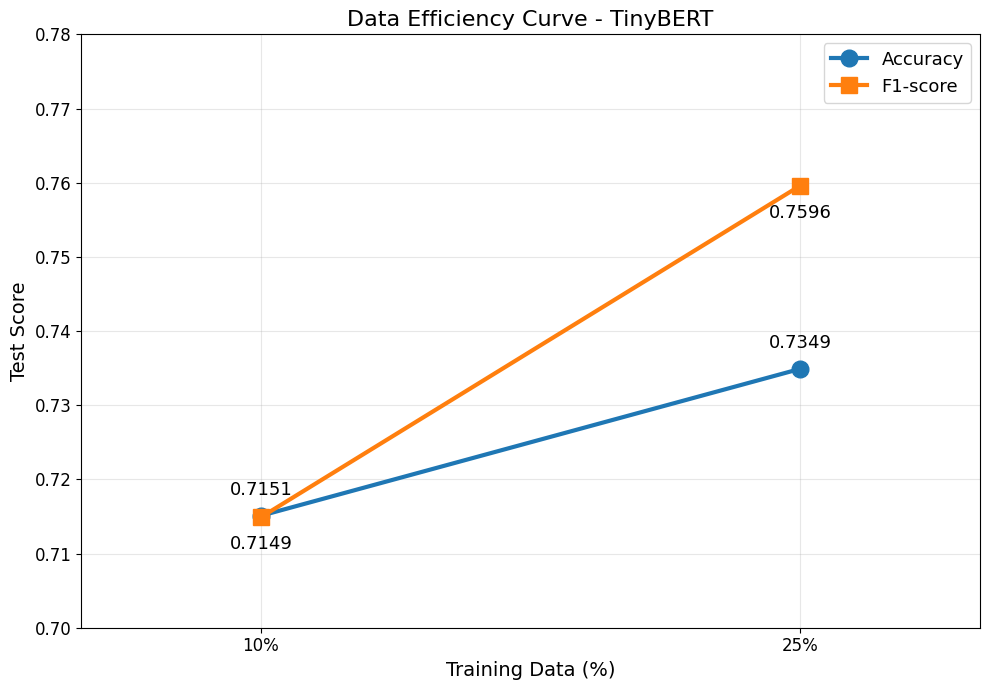

In [95]:
import matplotlib.pyplot as plt

# Chuyển "10%", "25%" thành 10, 25 để vẽ
x = (
    df_experiment3["Data Ratio"]
    .str.rstrip("%")
    .astype(float)
)

plt.figure(figsize=(10, 7))

plt.plot(
    x,
    df_experiment3["Accuracy"],
    marker="o",
    markersize=12,
    linewidth=3,
    label="Accuracy"
)

plt.plot(
    x,
    df_experiment3["F1"],
    marker="s",
    markersize=12,
    linewidth=3,
    label="F1-score"
)

for i, row in df_experiment3.iterrows():
    plt.annotate(
        f'{row["Accuracy"]:.4f}',
        (x.loc[i], row["Accuracy"]),
        xytext=(0, 15),
        textcoords="offset points",
        ha="center",
        fontsize=13
    )

    plt.annotate(
        f'{row["F1"]:.4f}',
        (x.loc[i], row["F1"]),
        xytext=(0, -23),
        textcoords="offset points",
        ha="center",
        fontsize=13
    )

plt.xlabel("Training Data (%)", fontsize=14)
plt.ylabel("Test Score", fontsize=14)
plt.title("Data Efficiency Curve - TinyBERT", fontsize=16)

plt.xlim(5, 30)
plt.ylim(0.70, 0.78)

plt.xticks([10, 25], ["10%", "25%"], fontsize=12)
plt.yticks(fontsize=12)

plt.grid(alpha=0.3)
plt.legend(fontsize=13)
plt.tight_layout()

plt.savefig("data_efficiency.png", dpi=300)
plt.show()

# 17. Experiment 4 — Maximum Sequence Length

In [38]:
from sklearn.model_selection import train_test_split

DATA_RATIOS = [0.1]

def create_training_subset(train_df, ratio):
    if ratio == 1.0:
        return train_df.copy().reset_index(drop=True)

    subset_df, _ = train_test_split(
        train_df,
        train_size=ratio,
        stratify=train_df["label"],
        random_state=42
    )

    return subset_df.reset_index(drop=True)


for ratio in DATA_RATIOS:
    subset = create_training_subset(train_df, ratio)

    print(
        f"{ratio * 100:>5.0f}%: "
        f"{len(subset):,} samples"
    )

   10%: 3,009 samples


In [39]:
len(subset)

3009

In [40]:
import numpy as np
import torch
import torch.nn.functional as F

def predict_pretrained(model, loader):

    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = F.softmax(
                outputs.logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probs.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

In [41]:
experiment4_predictions = {}

In [42]:
MAX_LENGTHS = [64, 128, 256]

experiment4_results = []

In [47]:
import psutil
import os
import torch
import pandas as pd

process = psutil.Process(os.getpid())

for max_len in MAX_LENGTHS:

    print(f"\n{'=' * 50}")
    print(f"Maximum Sequence Length: {max_len}")
    print(f"{'=' * 50}")

    # Create datasets
    train_dataset = IMDbTransformerDataset(
        subset["words"],
        subset["label"],
        tokenizer,
        max_len
    )

    val_dataset = IMDbTransformerDataset(
        val_df["words"],
        val_df["label"],
        tokenizer,
        max_len
    )

    test_dataset = IMDbTransformerDataset(
        test_df["words"],
        test_df["label"],
        tokenizer,
        max_len
    )

    # Create DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Initialize a fresh pretrained model
    torch.manual_seed(42)

    pretrained_model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=2
        ).to(DEVICE)
    )

    # Reset GPU memory statistics
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)

    cpu_memory_before = (
        process.memory_info().rss / (1024 ** 2)
    )

    # Training
    pretrained_model, training_time = train_pretrained(
        pretrained_model,
        train_loader,
        val_loader,
        epochs=EPOCHS,
        learning_rate=2e-5
    )

    # Evaluation
    test_metrics = evaluate_pretrained(
        pretrained_model,
        test_loader
    )

    # Measure memory
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

        gpu_memory = (
            torch.cuda.max_memory_allocated(DEVICE)
            / (1024 ** 2)
        )
    else:
        gpu_memory = 0.0

    cpu_memory_after = (
        process.memory_info().rss / (1024 ** 2)
    )

    experiment4_results.append({
        "Max length": max_len,
        "Accuracy": test_metrics["accuracy"],
        "F1": test_metrics["f1"],
        "Training time (s)": training_time,
        "GPU memory (MB)": gpu_memory,
        "CPU memory (MB)": cpu_memory_after
    })

    print(f"Accuracy: {test_metrics['accuracy']:.4f}")
    print(f"F1: {test_metrics['f1']:.4f}")
    print(f"Training time: {training_time:.2f}s")
    print(f"GPU memory: {gpu_memory:.2f} MB")
    print(f"CPU memory: {cpu_memory_after:.2f} MB")


    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


Maximum Sequence Length: 64


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6670 | Val Accuracy: 0.6286 | Val F1: 0.5725
Epoch 2/5 | Loss: 0.6213 | Val Accuracy: 0.6460 | Val F1: 0.6286
Epoch 3/5 | Loss: 0.5898 | Val Accuracy: 0.6490 | Val F1: 0.6288
Epoch 4/5 | Loss: 0.5618 | Val Accuracy: 0.6658 | Val F1: 0.6606
Epoch 5/5 | Loss: 0.5327 | Val Accuracy: 0.6490 | Val F1: 0.5816
Accuracy: 0.6524
F1: 0.5809
Training time: 181.69s
GPU memory: 593.49 MB
CPU memory: 2193.17 MB

Maximum Sequence Length: 128


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6598 | Val Accuracy: 0.6546 | Val F1: 0.5985
Epoch 2/5 | Loss: 0.5900 | Val Accuracy: 0.6921 | Val F1: 0.7145
Epoch 3/5 | Loss: 0.5498 | Val Accuracy: 0.6994 | Val F1: 0.7040
Epoch 4/5 | Loss: 0.5099 | Val Accuracy: 0.7027 | Val F1: 0.7091
Epoch 5/5 | Loss: 0.4817 | Val Accuracy: 0.7015 | Val F1: 0.6851
Accuracy: 0.6990
F1: 0.6789
Training time: 199.63s
GPU memory: 774.51 MB
CPU memory: 2220.41 MB

Maximum Sequence Length: 256


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6544 | Val Accuracy: 0.7102 | Val F1: 0.7301
Epoch 2/5 | Loss: 0.5518 | Val Accuracy: 0.7321 | Val F1: 0.7465
Epoch 3/5 | Loss: 0.5090 | Val Accuracy: 0.7398 | Val F1: 0.7434
Epoch 4/5 | Loss: 0.4444 | Val Accuracy: 0.7418 | Val F1: 0.7631
Epoch 5/5 | Loss: 0.4100 | Val Accuracy: 0.7296 | Val F1: 0.6934
Accuracy: 0.7240
F1: 0.6835
Training time: 265.32s
GPU memory: 1159.85 MB
CPU memory: 2220.89 MB


In [54]:
    pretrained_model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=2
        ).to(DEVICE)
    )

pretrained_model, training_time = train_pretrained(
        pretrained_model,
        train_loader,
        val_loader,
        epochs=EPOCHS,
        learning_rate=2e-5
    )

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/arch

Epoch 1/5 | Loss: 0.6782 | Val Accuracy: 0.6963 | Val F1: 0.6525
Epoch 2/5 | Loss: 0.5647 | Val Accuracy: 0.7307 | Val F1: 0.7285
Epoch 3/5 | Loss: 0.5027 | Val Accuracy: 0.7354 | Val F1: 0.7477
Epoch 4/5 | Loss: 0.4536 | Val Accuracy: 0.7391 | Val F1: 0.7517
Epoch 5/5 | Loss: 0.4093 | Val Accuracy: 0.7305 | Val F1: 0.7619


In [48]:
import pandas as pd
df_experiment4 = pd.DataFrame(
    experiment4_results
)

display(
    df_experiment4.style.format({
        "Accuracy": "{:.4f}",
        "F1": "{:.4f}",
        "Training time (s)": "{:.2f}",
        "GPU memory (MB)": "{:.2f}",
        "CPU memory (MB)": "{:.2f}"
    }).set_caption(
        "Experiment 4 — Maximum Sequence Length"
    )
)

,Max length,Accuracy,F1,Training time (s),GPU memory (MB),CPU memory (MB)
0,64,0.6524,0.5809,181.69,593.49,2193.17
1,128,0.6990,0.6789,199.63,774.51,2220.41
2,256,0.7240,0.6835,265.32,1159.85,2220.89


In [55]:
# Evaluate on test set
test_metrics = evaluate_pretrained(
    pretrained_model,
    test_loader
)

# Get predictions and probabilities
y_true, y_pred, y_probs = predict_pretrained(
    pretrained_model,
    test_loader
)

experiment4_predictions[max_len] = {
    "y_true": y_true,
    "y_pred": y_pred,
    "y_probs": y_probs
}

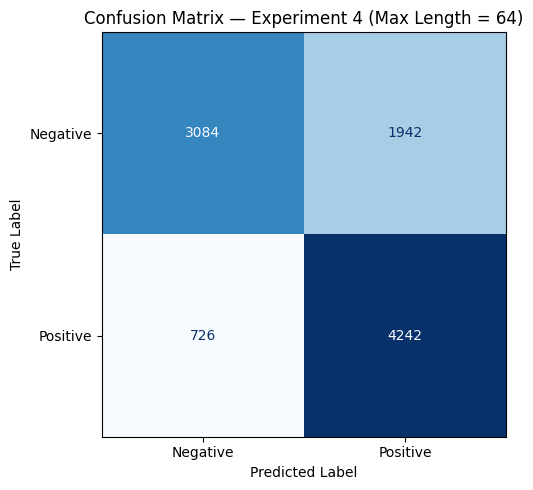

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

max_len = 64
y_true = experiment4_predictions[max_len]["y_true"]
y_pred = experiment4_predictions[max_len]["y_pred"]

# Tính toán ma trận nhầm lẫn
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Khởi tạo đối tượng hiển thị
display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Negative", "Positive"]
)

# Tạo khung hình đơn lẻ với kích thước cân đối
fig, ax = plt.subplots(figsize=(6, 5))

display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

# Đặt tiêu đề và nhãn trục
ax.set_title(
    f"Confusion Matrix — Experiment 4 (Max Length = {max_len})", fontsize=12
)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()


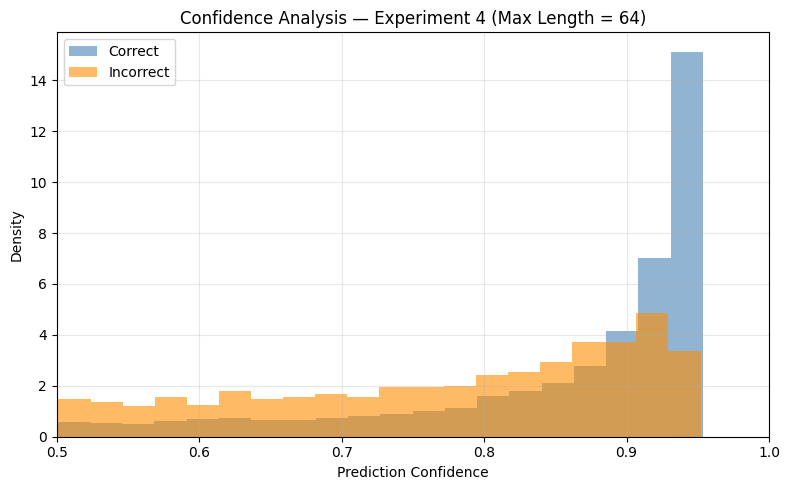

In [62]:
import matplotlib.pyplot as plt
import numpy as np

max_len = 64
data = experiment4_predictions[max_len]

y_true = np.array(data["y_true"])
y_pred = np.array(data["y_pred"])
y_probs = np.array(data["y_probs"])

# Độ tự tin (confidence) của lớp được dự đoán
confidence = np.max(y_probs, axis=1)

# Tách riêng các dự đoán đúng và sai
correct_mask = y_true == y_pred
correct_confidence = confidence[correct_mask]
incorrect_confidence = confidence[~correct_mask]

# Tạo biểu đồ đơn lẻ
plt.figure(figsize=(8, 5))

plt.hist(
    correct_confidence,
    bins=20,
    alpha=0.6,
    density=True,
    label="Correct",
    color="steelblue",
)

plt.hist(
    incorrect_confidence,
    bins=20,
    alpha=0.6,
    density=True,
    label="Incorrect",
    color="darkorange",
)

plt.title(
    f"Confidence Analysis — Experiment 4 (Max Length = {max_len})", fontsize=12
)
plt.xlabel("Prediction Confidence")
plt.ylabel("Density")
plt.xlim(0.5, 1.0)  # Thường xác suất dự đoán cao nhất trong bài toán 2 nhãn nằm từ 0.5 đến 1.0
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig("confidence_analysis.png", dpi=300, bbox_inches="tight")

plt.show()


# 18. Experiment 5 — Domain Shift

In [65]:
from datasets import load_dataset

# Thêm tiền tố 'fancyzhx/' để đúng chuẩn namespace/name
amazon_dataset = load_dataset("fancyzhx/amazon_polarity", split="test")

# Lấy 5,000 samples để thực nghiệm
amazon_dataset = amazon_dataset.shuffle(seed=42).select(range(5000))

print(amazon_dataset)
print(amazon_dataset[0])


README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00002-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  255MB            

... (4 outputs left out)

amazon_polarity/test-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'title', 'content'],
    num_rows: 5000
})
{'label': 1, 'title': 'Damaged Product', 'content': 'The product works fine. I ordered the more exprensive one after I read reviews from others on Amazon. My husband likes the presser. It does a good job pressing his pants. However, it was damaged in the box when we received it. We decided it was too much trouble to send it back. The box was torn and the presser had a chuck knocked out of it.'}


In [66]:
amazon_texts = [
    f"{item['title']}. {item['content']}"
    for item in amazon_dataset
]

amazon_labels = [
    item["label"]
    for item in amazon_dataset
]

amazon_test_dataset = IMDbTransformerDataset(
    amazon_texts,
    amazon_labels,
    tokenizer,
    MAX_LENGTH
)

amazon_test_loader = DataLoader(
    amazon_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Amazon test samples:", len(amazon_test_dataset))

Amazon test samples: 5000


In [68]:
# In-domain evaluation: IMDb
imdb_metrics = evaluate_pretrained(
    pretrained_model,
    test_loader
)

# Out-of-domain evaluation: Amazon
amazon_metrics = evaluate_pretrained(
    pretrained_model,
    amazon_test_loader
)

print("IMDb Test Results:")
print(imdb_metrics)

print("\nAmazon Test Results:")
print(amazon_metrics)

IMDb Test Results:
{'accuracy': 0.7330398238943366, 'precision': 0.6859637774902976, 'recall': 0.8538647342995169, 'f1': 0.7607604017216643}

Amazon Test Results:
{'accuracy': 0.8604, 'precision': 0.842534271952575, 'recall': 0.8928150765606596, 'f1': 0.8669462447579108}


In [72]:
from IPython.display import display
import pandas as pd

domain_results = pd.DataFrame([
    {
        "Domain": "IMDb Movie Reviews",
        "Evaluation": "In-domain",
        "Accuracy": imdb_metrics["accuracy"],
        "Precision": imdb_metrics["precision"],
        "Recall": imdb_metrics["recall"],
        "F1": imdb_metrics["f1"],
    },
    {
        "Domain": "Amazon Product Reviews",
        "Evaluation": "Out-of-domain",
        "Accuracy": amazon_metrics["accuracy"],
        "Precision": amazon_metrics["precision"],
        "Recall": amazon_metrics["recall"],
        "F1": amazon_metrics["f1"],
    },
])

display(
    domain_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
    }).set_caption("Experiment 5 — Domain Shift Evaluation")
)


,Domain,Evaluation,Accuracy,Precision,Recall,F1
0,IMDb Movie Reviews,In-domain,0.7330,0.6860,0.8539,0.7608
1,Amazon Product Reviews,Out-of-domain,0.8604,0.8425,0.8928,0.8669


In [73]:
domain_drop = pd.DataFrame([
    {
        "Metric": metric.capitalize(),
        "IMDb": imdb_metrics[metric],
        "Amazon": amazon_metrics[metric],
        "Performance Drop": (
            imdb_metrics[metric] - amazon_metrics[metric]
        ),
        "Relative Drop (%)": (
            (imdb_metrics[metric] - amazon_metrics[metric])
            / imdb_metrics[metric] * 100
        )
    }
    for metric in [
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
])

display(
    domain_drop.style.format({
        "IMDb": "{:.4f}",
        "Amazon": "{:.4f}",
        "Performance Drop": "{:.4f}",
        "Relative Drop (%)": "{:.2f}%"
    }).set_caption("Performance Degradation under Domain Shift")
)

,Metric,IMDb,Amazon,Performance Drop,Relative Drop (%)
0,Accuracy,0.7330,0.8604,-0.1274,-17.37%
1,Precision,0.6860,0.8425,-0.1566,-22.82%
2,Recall,0.8539,0.8928,-0.0390,-4.56%
3,F1,0.7608,0.8669,-0.1062,-13.96%


# 19. Application — Sentiment Classification

In [74]:
import numpy as np
import torch
import torch.nn.functional as F

def predict_pretrained(model, loader):

    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probs = F.softmax(
                outputs.logits,
                dim=1
            )

            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

In [76]:
imdb_true, imdb_pred, imdb_probs = predict_pretrained(
    pretrained_model,
    test_loader
)

amazon_true, amazon_pred, amazon_probs = predict_pretrained(
    pretrained_model,
    amazon_test_loader
)

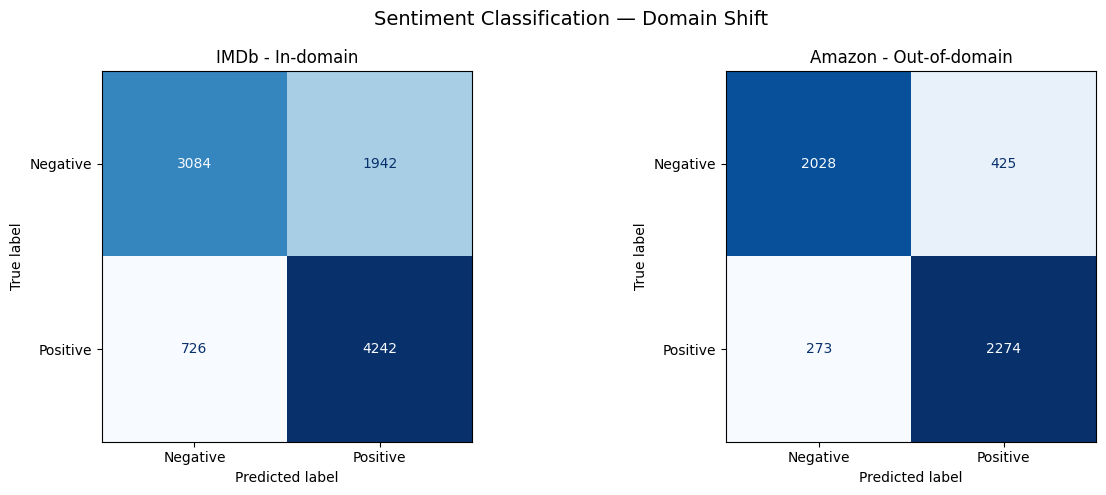

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

datasets_results = [
    ("IMDb - In-domain", imdb_true, imdb_pred),
    ("Amazon - Out-of-domain", amazon_true, amazon_pred)
]

for ax, (title, y_true, y_pred) in zip(
    axes,
    datasets_results
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(title)

plt.suptitle(
    "Sentiment Classification — Domain Shift",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "domain_shift_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

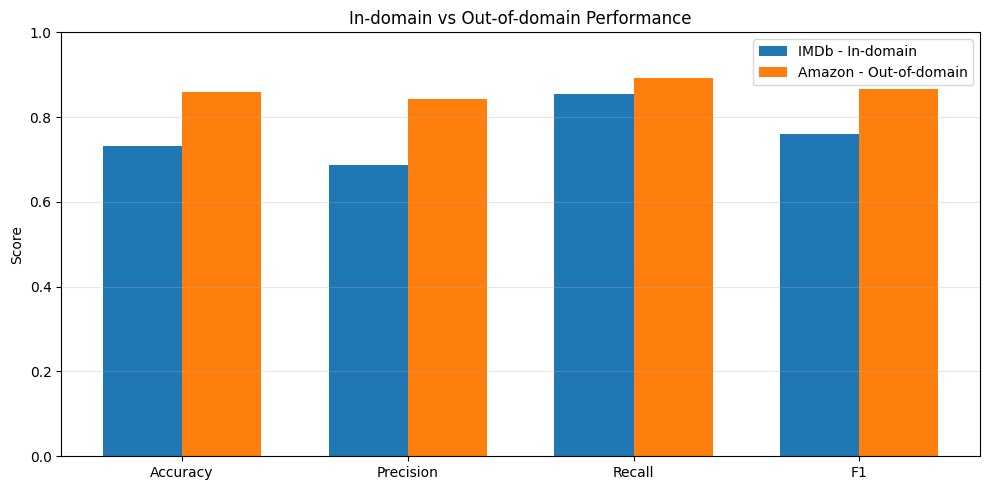

In [78]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]

x = np.arange(len(metrics))
width = 0.35

imdb_values = [
    imdb_metrics[m.lower()]
    for m in metrics
]

amazon_values = [
    amazon_metrics[m.lower()]
    for m in metrics
]

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    imdb_values,
    width,
    label="IMDb - In-domain"
)

plt.bar(
    x + width / 2,
    amazon_values,
    width,
    label="Amazon - Out-of-domain"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("In-domain vs Out-of-domain Performance")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "domain_shift_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
def predict_sentiment(text, model, tokenizer):

    model.eval()

    encoding = tokenizer(
        text,
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    input_ids = encoding["input_ids"].to(DEVICE)
    attention_mask = encoding["attention_mask"].to(DEVICE)

    with torch.no_grad():

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = F.softmax(
            outputs.logits,
            dim=1
        )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    confidence = probabilities[0, predicted_class].item()

    sentiment = (
        "Positive"
        if predicted_class == 1
        else "Negative"
    )

    return {
        "review": text,
        "sentiment": sentiment,
        "confidence": confidence
    }

In [80]:
reviews = [
    "This movie is absolutely wonderful. "
    "The acting and storyline are amazing.",

    "The product is terrible. "
    "It stopped working after two days.",

    "I expected much more. "
    "The quality is disappointing."
]

for review in reviews:

    result = predict_sentiment(
        review,
        pretrained_model,
        tokenizer
    )

    print("Review:", result["review"])
    print("Sentiment:", result["sentiment"])
    print(
        f"Confidence: {result['confidence']:.4f}"
    )
    print("-" * 60)

Review: This movie is absolutely wonderful. The acting and storyline are amazing.
Sentiment: Positive
Confidence: 0.9139
------------------------------------------------------------
Review: The product is terrible. It stopped working after two days.
Sentiment: Negative
Confidence: 0.9438
------------------------------------------------------------
Review: I expected much more. The quality is disappointing.
Sentiment: Negative
Confidence: 0.9365
------------------------------------------------------------
